### Verzinkt – Lösung Schritt für Schritt

*41. Bundeswettbewerb Informatik (2022), 1. Runde, Aufgabe 2*

Muster wie im Bild der Aufgabe sieht man an feuerverzinkten Metallen, zum Beispiel an den Masten von Laternen oder Ampeln. Sie
entstehen, indem sich beim Erkalten des flüssigen Zinks von zufällig vorhandenen Kristallisationskeimen aus Kristalle bilden.
Jeder Keim hat eine bestimmte Orientierung. Um ihn herum wächst ein Kristall mit der gleichen Orientierung, bis er auf andere
Kristalle trifft. Kristalle unterschiedlicher Orientierung reflektieren das Licht unterschiedlich und erscheinen so
unterschiedlich hell.

#### Aufgabe 2

Schreibe ein Programm, das die Entstehung solcher Muster simuliert. Vorgaben:

- Der Ort eines Keims ist ein Punkt in einem zweidimensionalen Raster.
- Von einem Keim aus wächst der Kristall schrittweise nach links, rechts, oben und unten.
- Für jede dieser Richtungen hat ein Kristall eigene Wachstumsgeschwindigkeiten.
- Ein Kristall wächst so weit wie möglich, aber nicht in die Fläche eines anderen Kristalls hinein.
- Die unterschiedlichen Lichtreflektionen werden als Grautöne dargestellt.

Variiert werden sollen unter anderem Anzahl und Orte der Keime, Entstehungszeitpunkte und Wachstumsgeschwindigkeiten.
Visualisiere die Muster als Pixelbilder. Mit welchen Werten für die Parameter erhältst du Bilder, die dem Bild der Aufgabe
ähneln?

Beispieldaten gibt es zu dieser Aufgabe nicht.

## Was dir bei dieser Aufgabe hilft

**Algorithmische Kenntnisse**
- **Simulation:** Man bildet den Vorgang im Rechner nach, hier das Wachstum von Kristallen auf einem Raster.
- **Ereignisse in zeitlicher Reihenfolge abarbeiten (Prioritätswarteschlange):** Wir merken uns „Zelle Z wird zur Zeit t von
  Kristall K erreicht“ und bearbeiten immer das Ereignis mit der kleinsten Zeit zuerst. Das ist dasselbe Prinzip wie beim
  Dijkstra-Algorithmus.
- **Zufall mit festem Startwert:** Mit `random.seed(...)` kann man dieselben „zufälligen“ Bilder jederzeit neu erzeugen.

**Nützliche Funktionen und Bibliotheken**
- `heapq.heappush` und `heapq.heappop`: Liste, aus der man immer das kleinste Element herausholt
- `random.randrange`, `random.uniform`, `random.shuffle`: Zufallszahlen
- `matplotlib.pyplot.imshow`: eine Tabelle von Zahlen als Pixelbild mit Grautönen zeigen

## Die Idee

**Warum nicht einfach „Schritt für Schritt alle Kristalle ein Kästchen größer machen“?** Dann könnten die Kristalle nur ganze
Kästchen pro Schritt wachsen, also wären Geschwindigkeiten wie „0,37 Kästchen pro Zeiteinheit“ nicht darstellbar. Außerdem wäre
unklar, wer gewinnt, wenn zwei Kristalle im selben Schritt dasselbe Kästchen wollen.

**Besser: Zeit statt Schritte.** Jeder Keim bekommt für jede Richtung eine **Dauer**: wie lange er braucht, um von einem Kästchen
in das Nachbarkästchen in dieser Richtung zu wachsen. Eine kleine Dauer bedeutet schnelles Wachstum. Dann gilt:

1. Wir führen eine Liste von Ereignissen „Kristall K erreicht Kästchen Z zur Zeit t“. Am Anfang steht dort jeder Keim mit
   seinem Entstehungszeitpunkt.
2. Wir nehmen immer das Ereignis mit der **kleinsten Zeit**. Ist das Kästchen noch frei, gehört es ab jetzt zu Kristall K. Dann
   tragen wir die (freien) Nachbarkästchen ein, und zwar mit der Zeit `t + Dauer in dieser Richtung`.
3. Ist das Kästchen schon belegt, tun wir nichts. So kann kein Kristall in einen anderen hineinwachsen oder durch ihn hindurch:
   Er kommt an einem belegten Kästchen nicht weiter, denn von dort aus werden keine Nachbarn eingetragen.
4. Wir hören auf, wenn die Liste leer ist (dann ist jedes Kästchen belegt, vorausgesetzt es gibt mindestens einen Keim).

Auch **spät entstehende Keime** fügen sich ein: Ein Keim kommt mit seiner Startzeit in die Liste. Ist sein Kästchen bis dahin
schon von einem anderen Kristall belegt, passiert nichts, der Keim „ertrinkt“ im fremden Kristall. Genau so verhält sich ein
echter Keim, der sich mitten in einem schon fertigen Kristall nicht mehr bilden kann.

Die „Liste, aus der man das Kleinste herausholt“ ist die Prioritätswarteschlange. In Python gibt es dafür das Modul `heapq`:
`heappush(liste, element)` legt ein Element ab, `heappop(liste)` liefert das kleinste. Bei Tupeln zählt zuerst die erste
Zahl, wir stellen also die Zeit an den Anfang.

## Schritt 1: Die Simulation

Ein **Keim** ist ein Dictionary mit dem Ort `x`, `y`, dem Entstehungszeitpunkt `start` und der Liste `dauer` mit den vier Zeiten
für links, rechts, oben, unten (in dieser Reihenfolge, passend zu `RICHTUNGEN`). Das Raster ist eine Liste von Zeilen; in
`bild[y][x]` steht die Nummer des Keims, zu dem das Kästchen gehört, und `-1` für „noch frei“.

Ein Eintrag der Warteschlange ist `(zeit, x, y, nummer)`. Haben zwei Einträge dieselbe Zeit, entscheidet der Vergleich der
weiteren Zahlen; das ist ein reiner Zufall am Rand und für das Bild ohne Bedeutung.

In [ ]:
import heapq

# Richtungen: links, rechts, oben, unten (Verschiebung in x und y)
RICHTUNGEN = [(-1, 0), (1, 0), (0, -1), (0, 1)]


def simuliere(breite, hoehe, keime):
    bild = [[-1] * breite for _ in range(hoehe)]        # -1 = frei
    warteschlange = []
    for nummer in range(len(keime)):
        k = keime[nummer]
        heapq.heappush(warteschlange, (k['start'], k['x'], k['y'], nummer))

    while len(warteschlange) > 0:
        zeit, x, y, nummer = heapq.heappop(warteschlange)   # kleinste Zeit zuerst
        if bild[y][x] != -1:
            continue                                        # schon belegt: nichts tun
        bild[y][x] = nummer                                 # Kästchen gehört jetzt zum Kristall
        for r in range(4):                                  # Nachbarn eintragen
            nx = x + RICHTUNGEN[r][0]
            ny = y + RICHTUNGEN[r][1]
            if 0 <= nx < breite and 0 <= ny < hoehe and bild[ny][nx] == -1:
                dauer = keime[nummer]['dauer'][r]
                heapq.heappush(warteschlange, (zeit + dauer, nx, ny, nummer))
    return bild

## Schritt 2: Ein erstes Beispiel von Hand

Drei Keime auf einem kleinen Raster (20 breit, 10 hoch). Alle entstehen zur Zeit 0. Keim 0 wächst überall gleich schnell
(Dauer 1), Keim 1 wächst nach links und rechts schnell (0,5), nach oben und unten langsam (2), Keim 2 wächst in alle Richtungen
langsam (1,5). Zur Textausgabe schreiben wir `0`, `1`, `2` für die Kristalle.

In [ ]:
keime = [
    {'x': 3, 'y': 2, 'start': 0, 'dauer': [1, 1, 1, 1]},
    {'x': 12, 'y': 5, 'start': 0, 'dauer': [0.5, 0.5, 2, 2]},
    {'x': 17, 'y': 1, 'start': 0, 'dauer': [1.5, 1.5, 1.5, 1.5]},
]
bild = simuliere(20, 10, keime)
for zeile in bild:
    print(''.join(str(nummer) for nummer in zeile))

00000000000022222222
00000000000122222222
00000000000111222222
00000000011111112222
00000001111111111111
00000111111111111111
00000111111111111111
00000011111111111111
00000001111111111111
00000001111111111111


Man sieht: Der schnelle Kristall `1` ist breit und flach und hat den Kristall `0` nach links zurückgedrängt, obwohl `0` zuerst
mit Dauer 1 pro Kästchen nach rechts wuchs. Die Grenzen verlaufen dort, wo sich zwei Kristalle zur gleichen Zeit treffen würden.
Der Kristall `2` rechts oben hat gar nicht genug Zeit, nach unten zu wachsen, weil `1` ihn schon begrenzt.

## Schritt 3: Zufällige Keime und Bilder

Für große Bilder würfeln wir die Keime. Die **Parameter**:

| Parameter | Bedeutung |
|---|---|
| `anzahl` | Zahl der Keime |
| `breite`, `hoehe` | Größe des Rasters |
| `tmin` | kleinste mögliche Dauer; jede der vier Dauern liegt zufällig zwischen `tmin` und 1 |
| `spaetestens` | Entstehungszeit eines Keims: zufällig zwischen 0 und `spaetestens` (0 heißt: alle Keime von Anfang an) |

Die Ortswahl ist gleichverteilt zufällig. Zwei Keime können auf demselben Kästchen landen; dann gewinnt der mit der früheren
Zeit, der andere verschwindet.

Dass `tmin` nicht 0 sein darf, hat einen Grund: Wählt man die Geschwindigkeit zufällig und rechnet in die Dauer um (Dauer =
1 / Geschwindigkeit), entstehen ein paar riesige Dauern, also fast stillstehende Kristalle. Mit zufälligen **Dauern** zwischen
`tmin` und 1 passiert das nicht.

**Grautöne:** Jeder Kristall bekommt einen eigenen Grauton. Wir verteilen `n` Töne gleichmäßig zwischen dunkelgrau (0,3) und fast
weiß (0,95) und mischen sie zufällig. So sind Nachbarn meist gut unterscheidbar.

In [ ]:
import random
import matplotlib.pyplot as plt


def zufallskeime(anzahl, breite, hoehe, tmin, spaetestens):
    keime = []
    for i in range(anzahl):
        keim = {'x': random.randrange(breite),
                'y': random.randrange(hoehe),
                'start': random.uniform(0, spaetestens),
                'dauer': [random.uniform(tmin, 1) for r in range(4)]}
        keime.append(keim)
    return keime


def grautoene(bild):
    """Ersetzt die Keimnummern durch Grauwerte (0 = schwarz, 1 = weiß), jeder vorkommende Kristall bekommt einen eigenen."""
    nummern = []
    for zeile in bild:
        for n in zeile:
            if n not in nummern:
                nummern.append(n)
    toene = list(range(len(nummern)))
    random.shuffle(toene)
    grau = {}
    for i in range(len(nummern)):
        grau[nummern[i]] = 0.3 + 0.65 * toene[i] / max(1, len(nummern) - 1)
    return [[grau[n] for n in zeile] for zeile in bild], len(nummern)


def kristallbild(achse, anzahl, tmin, spaetestens, breite=150, hoehe=150, startwert=1):
    random.seed(startwert)
    keime = zufallskeime(anzahl, breite, hoehe, tmin, spaetestens)
    bild = simuliere(breite, hoehe, keime)
    grau, kristalle = grautoene(bild)
    achse.imshow(grau, cmap='gray', vmin=0, vmax=1, interpolation='nearest')
    achse.set_title(str(anzahl) + ' Keime, tmin=' + str(tmin) + ', spätestens=' + str(spaetestens) + '\n'
                    + str(kristalle) + ' Kristalle sichtbar', fontsize=9)
    achse.axis('off')
    return kristalle

### Versuch 1: Anzahl der Keime (alle Keime von Anfang an, `tmin = 0.05`)

[10, 100, 984]


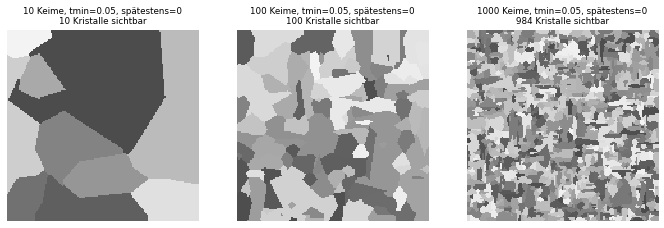

In [ ]:
figur, achsen = plt.subplots(1, 3, figsize=(12, 4.4))
anzahlen_kristalle = []
for achse, anzahl in zip(achsen, [10, 100, 1000]):
    anzahlen_kristalle.append(kristallbild(achse, anzahl, 0.05, 0))
print(anzahlen_kristalle)

Bei 10 Keimen sind alle 10 Kristalle sichtbar, bei 100 alle 100; bei 1000 Keimen sind es nur 984, weil manche Keime zufällig auf
demselben Kästchen liegen und dann einer verschwindet. Mit mehr Keimen werden die Kristalle kleiner.
Gemeinsam ist den Bildern: Alle Kristalle entstehen zur gleichen Zeit, es gibt keine kleinen „Splitter“ zwischen großen
Flächen. Das Original zeigt dagegen große und kleine Kristalle gemischt.

### Versuch 2: Mindestdauer `tmin`

Je kleiner `tmin`, desto größer ist der Unterschied zwischen schnellen und langsamen Kristallen. Bei `tmin = 0.01` überrennen
wenige schnelle Kristalle ihre Nachbarn und werden sehr lang gezogen; bei `tmin = 0.4` sind fast alle Kristalle ähnlich schnell
und ähnlich groß.

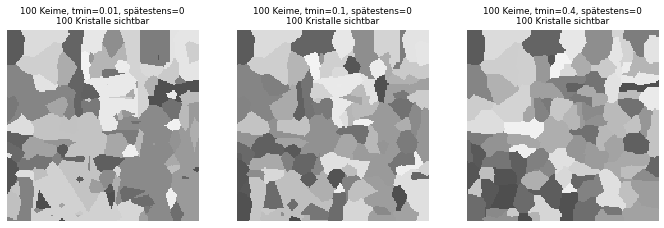

In [ ]:
figur, achsen = plt.subplots(1, 3, figsize=(12, 4.4))
for achse, tmin in zip(achsen, [0.01, 0.1, 0.4]):
    kristallbild(achse, 100, tmin, 0)

### Versuch 3: Spät entstehende Keime

Jetzt entstehen die Keime nach und nach. Ein Keim, der in einen schon vorhandenen Kristall fällt, geht verloren. Deshalb ist
die **Zahl der sichtbaren Kristalle** viel kleiner als die der gewürfelten Keime. Ein Kristall von 100 Keimen füllt das Raster in
etwa 7 Zeiteinheiten (Kantenlänge 150, typische Kristallbreite 15, Dauer etwa 0,5 je Kästchen), also machen wir `spaetestens = 6`.

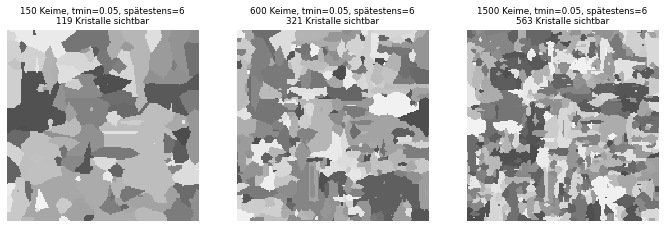

In [ ]:
figur, achsen = plt.subplots(1, 3, figsize=(12, 4.4))
for achse, anzahl in zip(achsen, [150, 600, 1500]):
    kristallbild(achse, anzahl, 0.05, 6)

Jetzt liegen deutlich weniger sichtbare Kristalle vor als gewürfelte Keime (119 von 150, 321 von 600, 563 von 1500), denn viele
Keime fallen in schon vorhandene Kristalle. Besonders bei 600 Keimen sieht man, was auch das Original ausmacht: Neben größeren
Kristallen gibt es kleine Flecken, die erst spät entstanden sind. Bei 1500 Keimen wird es zu kleinteilig.

### Ergebnis: Parameter, die dem Bild der Aufgabe ähneln

Wie in den Lösungshinweisen (dort mit sechseckigem Gitter) vergleichen wir mit vier Merkmalen des Originals: **(A)** mittelgroße
Kristalle mit geraden Kanten, **(B)** einzelne Zacken, die aus den Kanten ausbrechen, **(C)** verstreute kleine Flächen,
**(D)** Kristalle, die spitz zulaufen. Zacken und spitze Enden kommen von Kristallen, die in einer Richtung viel schneller als in der
anderen wachsen (große Unterschiede zwischen den vier Dauern, also kleines `tmin`). Kleine Flächen kommen von spät entstandenen
Keimen.

Wir kombinieren: 100 Keime bei Zeit 0 (sie bilden die großen Kristalle) und 400 Nachzügler bis Zeit 6, `tmin = 0.05`.

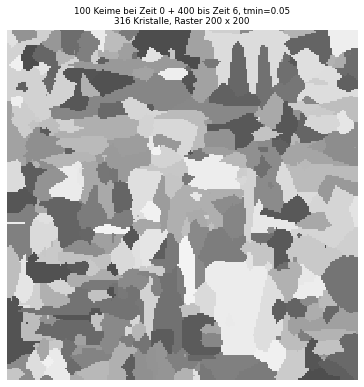

In [ ]:
def zwei_gruppen(breite, hoehe, tmin, anfangs, spaeter, spaetestens, startwert):
    random.seed(startwert)
    keime = zufallskeime(anfangs, breite, hoehe, tmin, 0) + zufallskeime(spaeter, breite, hoehe, tmin, spaetestens)
    return simuliere(breite, hoehe, keime)


figur, achse = plt.subplots(1, 1, figsize=(6.5, 6.5))
endbild = zwei_gruppen(200, 200, 0.05, 100, 400, 6, 4)
grau, kristalle = grautoene(endbild)
achse.imshow(grau, cmap='gray', vmin=0, vmax=1, interpolation='nearest')
achse.set_title('100 Keime bei Zeit 0 + 400 bis Zeit 6, tmin=0.05\n' + str(kristalle) + ' Kristalle, Raster 200 x 200', fontsize=9)
achse.axis('off')

Das Bild enthält die Zutaten des Originals: mittelgroße Flächen mit geraden Kanten, schmale Zacken (zum Beispiel oben), kleine
verstreute Flächen dazwischen. Kanten und Zacken zeigen allerdings nur in die vier Rasterrichtungen. Bei echtem Zink ist das Gitter
sechseckig; das kann man nachbauen (siehe „Für Neugierige“). Die Werte lassen sich als Antwort auf die Frage der Aufgabe festhalten:
**einige Dutzend Keime am Anfang, dazu weitere Keime, die über die Zeit entstehen (insgesamt etwa das Fünffache), und `tmin` um
0.05.**

## Prüfen, ob die Simulation stimmt

Wir prüfen drei Dinge:

1. **Jedes Kästchen ist belegt** (bei mindestens einem Keim).
2. **Jeder Kristall ist zusammenhängend.** Sonst wäre er durch einen anderen hindurchgewachsen oder gesprungen.
3. **Bei gleichen Dauern in alle Richtungen und gleichem Start** gehört jedes Kästchen zum Keim mit der kleinsten
   Manhattan-Entfernung (|Δx| + |Δy|). Das Ergebnis lässt sich so unabhängig nachrechnen.

In [ ]:
def ist_zusammenhaengend(bild, breite, hoehe, richtungen=RICHTUNGEN):
    """Prüft für jede Nummer: erreicht man alle Kästchen dieser Nummer vom ersten aus über Nachbarn derselben Nummer?"""
    for nummer in set(n for zeile in bild for n in zeile):
        kaestchen = set((x, y) for y in range(hoehe) for x in range(breite) if bild[y][x] == nummer)
        erstes = min(kaestchen)
        gesehen = {erstes}
        stapel = [erstes]
        while len(stapel) > 0:
            x, y = stapel.pop()
            for dx, dy in richtungen:
                nachbar = (x + dx, y + dy)
                if nachbar not in gesehen and nachbar in kaestchen:
                    gesehen.add(nachbar)
                    stapel.append(nachbar)
        if len(gesehen) != len(kaestchen):
            return False
    return True


# 1. und 2. mit zufälligen Keimen (mit Nachzüglern)
random.seed(7)
pruef_keime = zufallskeime(30, 40, 30, 0.05, 3)
pruef_bild = simuliere(40, 30, pruef_keime)
print('alle belegt:', all(n != -1 for zeile in pruef_bild for n in zeile))
print('zusammenhängend:', ist_zusammenhaengend(pruef_bild, 40, 30))

# 3. gleiche Dauern: Vergleich mit der Manhattan-Entfernung
random.seed(8)
gleich = []
for i in range(12):
    gleich.append({'x': random.randrange(40), 'y': random.randrange(30), 'start': 0, 'dauer': [1, 1, 1, 1]})
gleich_bild = simuliere(40, 30, gleich)
fehler = 0
for y in range(30):
    for x in range(40):
        entfernungen = [abs(k['x'] - x) + abs(k['y'] - y) for k in gleich]
        if entfernungen[gleich_bild[y][x]] != min(entfernungen):
            fehler += 1
print('Kästchen mit falschem Keim:', fehler)

alle belegt: True
zusammenhängend: True
Kästchen mit falschem Keim: 0


## Für Neugierige: Sechseckgitter

Echtes Zink kristallisiert in einem Sechseckgitter: Ein Kästchen hat sechs Nachbarn. Das lässt sich im Rechteckraster mit zwei
zusätzlichen Richtungen **schräg** nachbauen: Zu `(-1, 0)`, `(1, 0)`, `(0, -1)`, `(0, 1)` nehmen wir `(1, -1)` und `(-1, 1)`
hinzu. Die Simulation bleibt gleich, nur die Liste der Richtungen wird länger, und jeder Keim braucht sechs Dauern. Beim Zeichnen
versetzen wir Zeile `y` um `y // 2` Kästchen nach rechts („Scherung“), damit die Winkel ungefähr stimmen; die freien Ecken bleiben
weiß. Hier ein kurzer Versuch mit 150 x 150 Kästchen und 100 Keimen bei Zeit 0:

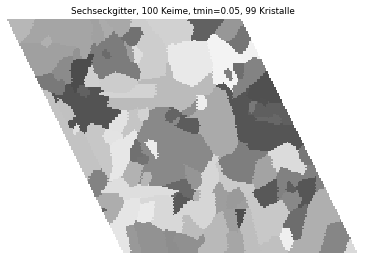

In [ ]:
RICHTUNGEN6 = [(-1, 0), (1, 0), (0, -1), (0, 1), (1, -1), (-1, 1)]


def simuliere6(breite, hoehe, keime):
    bild = [[-1] * breite for _ in range(hoehe)]
    warteschlange = []
    for nummer in range(len(keime)):
        heapq.heappush(warteschlange, (keime[nummer]['start'], keime[nummer]['x'], keime[nummer]['y'], nummer))
    while len(warteschlange) > 0:
        zeit, x, y, nummer = heapq.heappop(warteschlange)
        if bild[y][x] != -1:
            continue
        bild[y][x] = nummer
        for r in range(6):
            nx = x + RICHTUNGEN6[r][0]
            ny = y + RICHTUNGEN6[r][1]
            if 0 <= nx < breite and 0 <= ny < hoehe and bild[ny][nx] == -1:
                heapq.heappush(warteschlange, (zeit + keime[nummer]['dauer'][r], nx, ny, nummer))
    return bild


def schere(bild):
    """Verschiebt Zeile y um y // 2 Kästchen nach rechts; leere Stellen werden weiß."""
    hoehe = len(bild)
    breite = len(bild[0])
    neu = [[1.0] * (breite + hoehe // 2 + 1) for _ in range(hoehe)]
    for y in range(hoehe):
        for x in range(breite):
            neu[y][x + y // 2] = bild[y][x]
    return neu


random.seed(1)
keime6 = []
for i in range(100):
    keime6.append({'x': random.randrange(150), 'y': random.randrange(150), 'start': 0,
                   'dauer': [random.uniform(0.05, 1) for r in range(6)]})
bild6 = simuliere6(150, 150, keime6)
grau6, kristalle6 = grautoene(bild6)
figur, achse = plt.subplots(1, 1, figsize=(6.5, 6.5))
achse.imshow(schere(grau6), cmap='gray', vmin=0, vmax=1, interpolation='nearest')
achse.set_title('Sechseckgitter, 100 Keime, tmin=0.05, ' + str(kristalle6) + ' Kristalle', fontsize=9)
achse.axis('off')

Die Kanten haben jetzt sechs Richtungen, und es entstehen auch schräge Kanten. Die Lösungshinweise haben beide Gitter verglichen
und finden die Spitzen der Kristalle beim sechseckigen Gitter ähnlicher zum Original. Wir haben nur eine Zeichnung gemacht und
treffen dazu keine Aussage.

**Weitere Ideen:** Ein Torus (rechter Rand grenzt an linken Rand, oben an unten) lässt sich mit `% breite` und `% hoehe` bei den
Nachbarn einbauen; laut Hinweisen bringt das keine bessere Ähnlichkeit. Auch die Zahl der Nachzügler pro Zeiteinheit kann man von
der freien Fläche abhängig machen (die Hinweise nehmen dafür eine Poisson-Verteilung); bei unseren vorab gewürfelten Keimen passiert
das von selbst, weil Keime auf belegten Kästchen verschwinden.

**MiniZinc:** Für diese Aufgabe lassen wir es weg. Es gibt keine Bedingungen, die ein Solver lösen müsste, und nichts zu
optimieren: Es ist eine Simulation, deren Ergebnis ein Bild ist.